# RQ8: Does weather predict music mood beyond seasonal effects?

**Question:** Does daily weather genuinely predict music mood *beyond* seasonal effects? We compare a regression using weather features against a season/month-only baseline to test whether weather adds real predictive power, rather than just tracking the seasons (FR-15).

Reporting layer over the `Workflow 8` Snakemake outputs: it reads the results and adds interpretation. The analysis itself lives in the tested components under `src/Workflow 8/`.

## Method (in brief)

1. Aggregate the charts to a **daily** audio profile with that day's weather (`utils.aggregate_daily`) and attach the calendar features (`month`, `season`).
2. Fit two regressions of daily mean **valence** with the same estimator:
   - **baseline** -- month-of-year only (one-hot): the pure seasonal model;
   - **weather** -- month one-hot **plus** sunshine hours, precipitation and mean temperature.
3. Evaluate both on the **same held-out days** using a **chronological split** (last 20% of days, i.e. the year 2021). A random split would leak: consecutive chart days are strongly autocorrelated, and month dummies would be fit on days from the very period being predicted.
4. Two estimators are compared (ridge regression and a depth-limited random forest, pinned seed 42 per NFR-1) so the conclusion does not hinge on model choice.

Weather "adds real predictive power" only if the weather model beats the baseline out-of-sample (positive R-squared delta).

## How to reproduce

```bash
cd "src/Workflow 8"
snakemake -s SnakefileWorkflow8 --cores 1
```

This regenerates `results/workflow_8/model_comparison.csv` and `model_comparison.png`, which the cells below load.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

RESULTS = Path("..") / "results" / "workflow_8"
metrics = pd.read_csv(RESULTS / "model_comparison.csv")
metrics

,model,feature_set,n_train,n_test,r2,mae
0,ridge,baseline,1461,365,-0.369901,0.032483
1,ridge,weather,1461,365,-0.385313,0.032982
2,random_forest,baseline,1461,365,-0.359656,0.032388
3,random_forest,weather,1461,365,-0.334003,0.032528


In [2]:
pivot = metrics.pivot(index="model", columns="feature_set", values="r2")
pivot["delta_r2 (weather - baseline)"] = pivot["weather"] - pivot["baseline"]
pivot

feature_set,baseline,weather,delta_r2 (weather - baseline)
model,,,
random_forest,-0.359656,-0.334003,0.025653
ridge,-0.369901,-0.385313,-0.015412


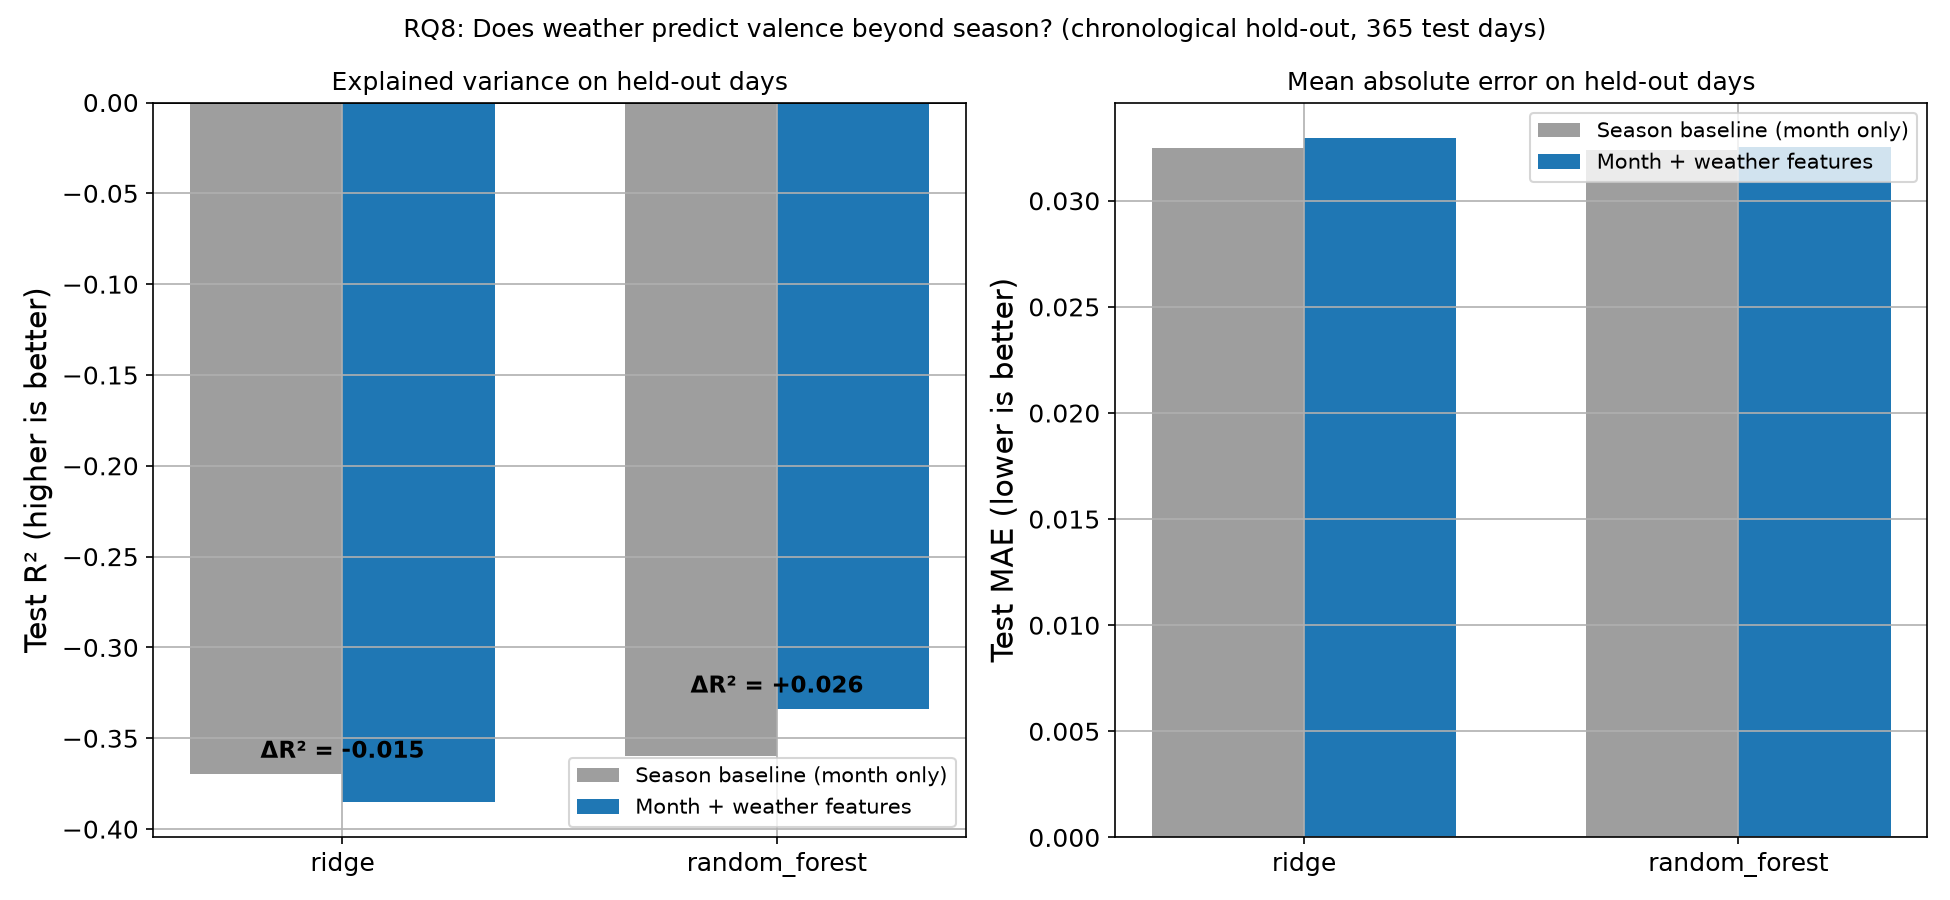

In [3]:
display(Image(filename=str(RESULTS / "model_comparison.png")))

## Findings

- **Weather adds essentially no predictive power beyond the calendar.** The R-squared delta between the weather model and the month-only baseline is tiny and not even consistent in sign: **-0.015** for ridge and **+0.026** for the random forest. MAE differences are similarly negligible (~0.0005 on a 0-1 valence scale, i.e. noise).
- **Both models fail to generalise to the held-out year at all** -- test R-squared is *negative* for every configuration (about -0.33 to -0.39). Predicting each 2021 day with the plain 2021 mean valence would have beaten both models. The month patterns learned from 2017-2020 do not transfer to 2021, because the charts' average valence drifts from year to year (repertoire changes, COVID-19 period) far more than any within-year weather signal.
- Absolute errors are still small (MAE around 0.032) because daily mean valence varies in a narrow band -- there is simply very little day-to-day variance for *any* predictor to explain.
- This closes the loop opened by **RQ1**: there, sunshine correlated with valence only *between* seasons, not within them. Here, formally, adding weather to a seasonal model does not improve out-of-sample mood prediction.

## Caveats

- **Year-to-year drift dominates.** The negative absolute R-squared values are a distribution-shift effect (train 2017-2020, test 2021), not a bug: the seasonal baseline itself fails to transfer. The *comparison* between the two models remains fair because both face identical conditions.
- **The COVID-19 period and cultural events** (Christmas music every December) move valence for non-weather reasons (NFR-12); December effects are partly absorbed by the month dummies, the pandemic shift is not.
- **Autocorrelation:** chart inertia means effective sample sizes are smaller than day counts; this favours neither model.
- **Specification:** weather enters linearly (plus tree interactions in the random forest); more elaborate feature engineering (lags, station-level weather) could in principle find signal this setup misses.

## Takeaway

**No -- once the seasonal cycle is accounted for, daily weather does not genuinely predict the mood of the German charts.** The weather-augmented model performs the same as the month-only baseline on held-out data (R-squared delta of -0.015 / +0.026 depending on estimator, MAE unchanged), and year-to-year drift in chart valence swamps both. The apparent weather-mood link in the pooled data (RQ1) is seasonal tracking, not weather signal.